## Loading imports and data

In [7]:
from FPCA import FPCA, Phimaker
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import geopandas as gpd
import contextily as ctx
import matplotlib.dates as mdates

In [ ]:
def partmissing(sensorseries):
    mask = ~np.isnan(sensorseries)
    if not mask.any(): return 100
    start_idx = np.argmax(mask)
    end_idx = len(sensorseries) - np.argmax(mask[::-1]) - 1
    series = sensorseries[start_idx:end_idx+1]
    return np.isnan(series).sum()/len(series) * 100

def partoutlier(sensorseries):
    mask = ~np.isnan(sensorseries)
    if not mask.any(): return None
    start_idx = np.argmax(mask)
    end_idx = len(sensorseries) - np.argmax(mask[::-1]) - 1
    series = sensorseries[start_idx:end_idx+1]

    nonmissing = np.sum(~np.isnan(series))
    outlier_count = np.sum(series > 500)
    return outlier_count / nonmissing * 100

def get_start_percentage(sensorseries):
    mask = ~np.isnan(sensorseries)
    start_idx = np.argmax(mask)
    return (start_idx / len(sensorseries)) * 100

def longest_high_run(sensorseries, threshold=500):
    mask = ~np.isnan(sensorseries)
    if not mask.any(): return None
    start_idx = np.argmax(mask)
    end_idx = len(sensorseries) - np.argmax(mask[::-1]) - 1
    series = sensorseries[start_idx:end_idx+1]

    high = series > threshold

    max_run = 0
    current = 0
    for x in high:
        if x:
            current += 1
            max_run = max(max_run, current)
        else:
            current = 0
    return max_run

def dataloader():
    raw_pollution = ...
    sensors = ...
    
    # Step 1: throw away completely useless sensors
    # Keep only viable sensors
    missing_rates = raw_pollution.apply(partmissing, axis=1)
    sensors['missing_rate'] = sensors.index.map(missing_rates)
    sensors = sensors[sensors['missing_rate'] < 50]
    raw_pollution = raw_pollution.loc[sensors.index]

    # Removing extreme outlier cases
    outlier_rates = raw_pollution.apply(partoutlier, axis=1)
    sensors['outlier_rate'] = sensors.index.map(outlier_rates)
    sensors = sensors[sensors['outlier_rate'] < 25]
    raw_pollution = raw_pollution.loc[sensors.index]

    # Removing consistent outlier sensors
    runs = raw_pollution.apply(longest_high_run, axis=1)
    sensors["max_high_run"] = sensors.index.map(runs)
    sensors = sensors[sensors.max_high_run < 14]
    raw_pollution = raw_pollution.loc[sensors.index]

    # Step 2: retrieving data that is viable for evaluating, but not usefull for training, not used in practice
    start_percentages = raw_pollution.apply(get_start_percentage, axis=1)
    sensors['start_at_percentage'] = raw_pollution.index.map(start_percentages)
    sensors_extra = sensors[sensors['start_at_percentage'] >= 50]
    sensors = sensors[sensors['start_at_percentage'] < 50]
    pollution_extra = raw_pollution.loc[sensors_extra.index]
    pollution = raw_pollution.loc[sensors.index]

    # Step 3: collecting all data
    dates = pd.to_datetime(raw_pollution.columns)
    longitude_extra = sensors_extra["longitude"].values
    latitude_extra = sensors_extra["latitude"].values
    pollution_extra = pollution_extra.values.T
    longitude = sensors["longitude"].values
    latitude = sensors['latitude'].values
    pollution = pollution.values.T
    pollution[pollution == 0] = np.nan

    return dates, longitude, latitude, pollution, longitude_extra, latitude_extra, pollution_extra

## Performing FPCA

In [9]:
def rescaler(x, eps = 0.01): return eps + (1 - 2*eps) * (x - np.min(x)) / (np.max(x) - np.min(x))

In [10]:
dates, longitude, latitude, pollution, _, _, _ = dataloader()
s1 = rescaler(longitude)
s2 = rescaler(latitude)
Phi = Phimaker(s1, s2)

Y_list = np.log(pollution)
Y_list_train = Y_list[:-365]
Y_list_test = Y_list[-365:]


T, N = Y_list.shape
r = 7
eigvals, Xi_truncated, Phi_eig, _,  Muhat, _ = FPCA(Y_list_train, Phi, Phi, r)
Level_list = np.tile(Muhat, (T,1))
Y_list = Y_list - Level_list
Y_list_train = Y_list[:-365]
Y_list_test = Y_list[-365:]

The selected 7 PCs explain 94.497% of the variance by using 7/49 PCs


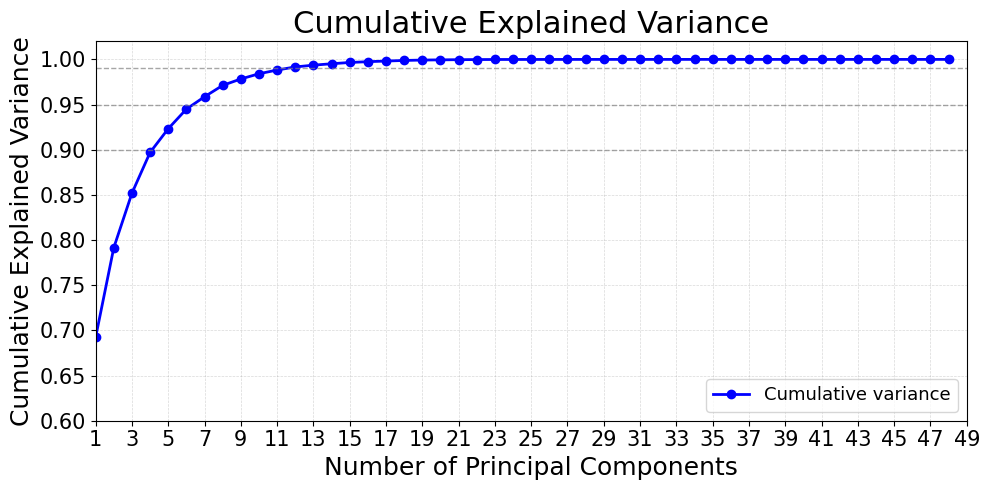

In [11]:
plt.figure(figsize=(10, 5))
plt.plot(
    eigvals.cumsum()/eigvals.sum(),
    marker='o',
    markersize=6,
    linewidth=2,
    color='blue',
    label="Cumulative variance"
)

# Threshold lines
plt.axhline(0.90, color='grey', linestyle='--', linewidth=1, alpha=0.7)
plt.axhline(0.95, color='grey', linestyle='--', linewidth=1, alpha=0.7)
plt.axhline(0.99, color='grey', linestyle='--', linewidth=1, alpha=0.7)



plt.xlabel("Number of Principal Components", fontsize=18)
plt.ylabel("Cumulative Explained Variance", fontsize=18)
plt.title("Cumulative Explained Variance", fontsize=22)

plt.xlim(1, len(eigvals))
plt.ylim(0.6, 1.02)

plt.xticks(
    np.arange(1, len(eigvals) + 1, 2),
    fontsize=15
)
plt.yticks(fontsize=15)

plt.grid(color='grey', linestyle='--', linewidth=0.5, alpha=0.3)
plt.legend(fontsize=13, loc='lower right')

plt.tight_layout()
plt.show()

## Plotting eigenfunctions

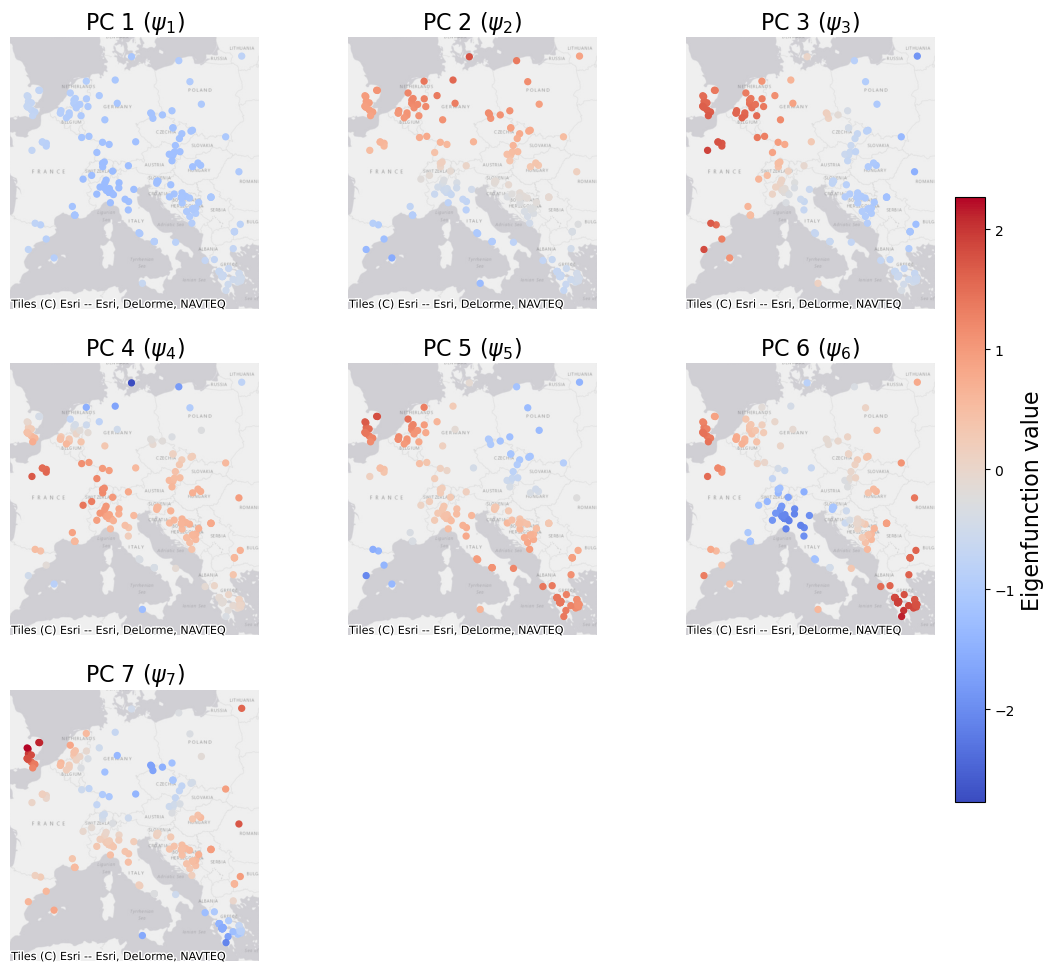

In [12]:
vmin = Phi_eig[:, :r].min()
vmax = Phi_eig[:, :r].max()

fig, axes = plt.subplots(3, 3, figsize=(13, 12))
axes = axes.flatten()

for l in range(r):
    ax = axes[l]

    gdf = gpd.GeoDataFrame(
        {'value': Phi_eig[:, l]},
        geometry=gpd.points_from_xy(longitude, latitude),
        crs="EPSG:4326"
    ).to_crs(epsg=3857)

    gdf.plot(
        ax=ax,
        column='value',
        cmap='coolwarm',
        vmin=vmin,
        vmax=vmax,
        markersize=18,
    )

    xmin, ymin, xmax, ymax = gdf.total_bounds
    x_pad = (xmax - xmin) * 0.08
    y_pad = (ymax - ymin) * 0.08

    ax.set_xlim(xmin - x_pad, xmax + x_pad)
    ax.set_ylim(ymin - y_pad, ymax + y_pad)

    ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas, zoom=5)

    ax.set_title(fr"PC {l+1} ($\psi_{l+1}$)", fontsize=16)
    ax.set_axis_off()

sm = plt.cm.ScalarMappable(
    cmap='coolwarm',
    norm=plt.Normalize(vmin=vmin, vmax=vmax)
)
sm._A = []

cbar = fig.colorbar(
    sm,
    ax=axes,
    orientation='vertical',
    fraction=0.03,
    pad=0.02
)
cbar.set_label("Eigenfunction value", fontsize=16)
for ax in axes[r:]:
    ax.set_axis_off()
plt.show()

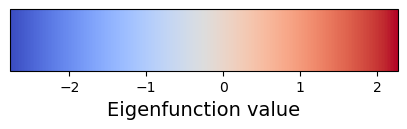

In [13]:
fig, ax = plt.subplots(figsize=(5, 0.8))

sm = plt.cm.ScalarMappable(
    cmap="coolwarm",
    norm=plt.Normalize(vmin=vmin, vmax=vmax)
)
sm.set_array([])

cbar = fig.colorbar(sm, cax=ax, orientation="horizontal")
cbar.set_label("Eigenfunction value", fontsize=14)

plt.show()
plt.close(fig)

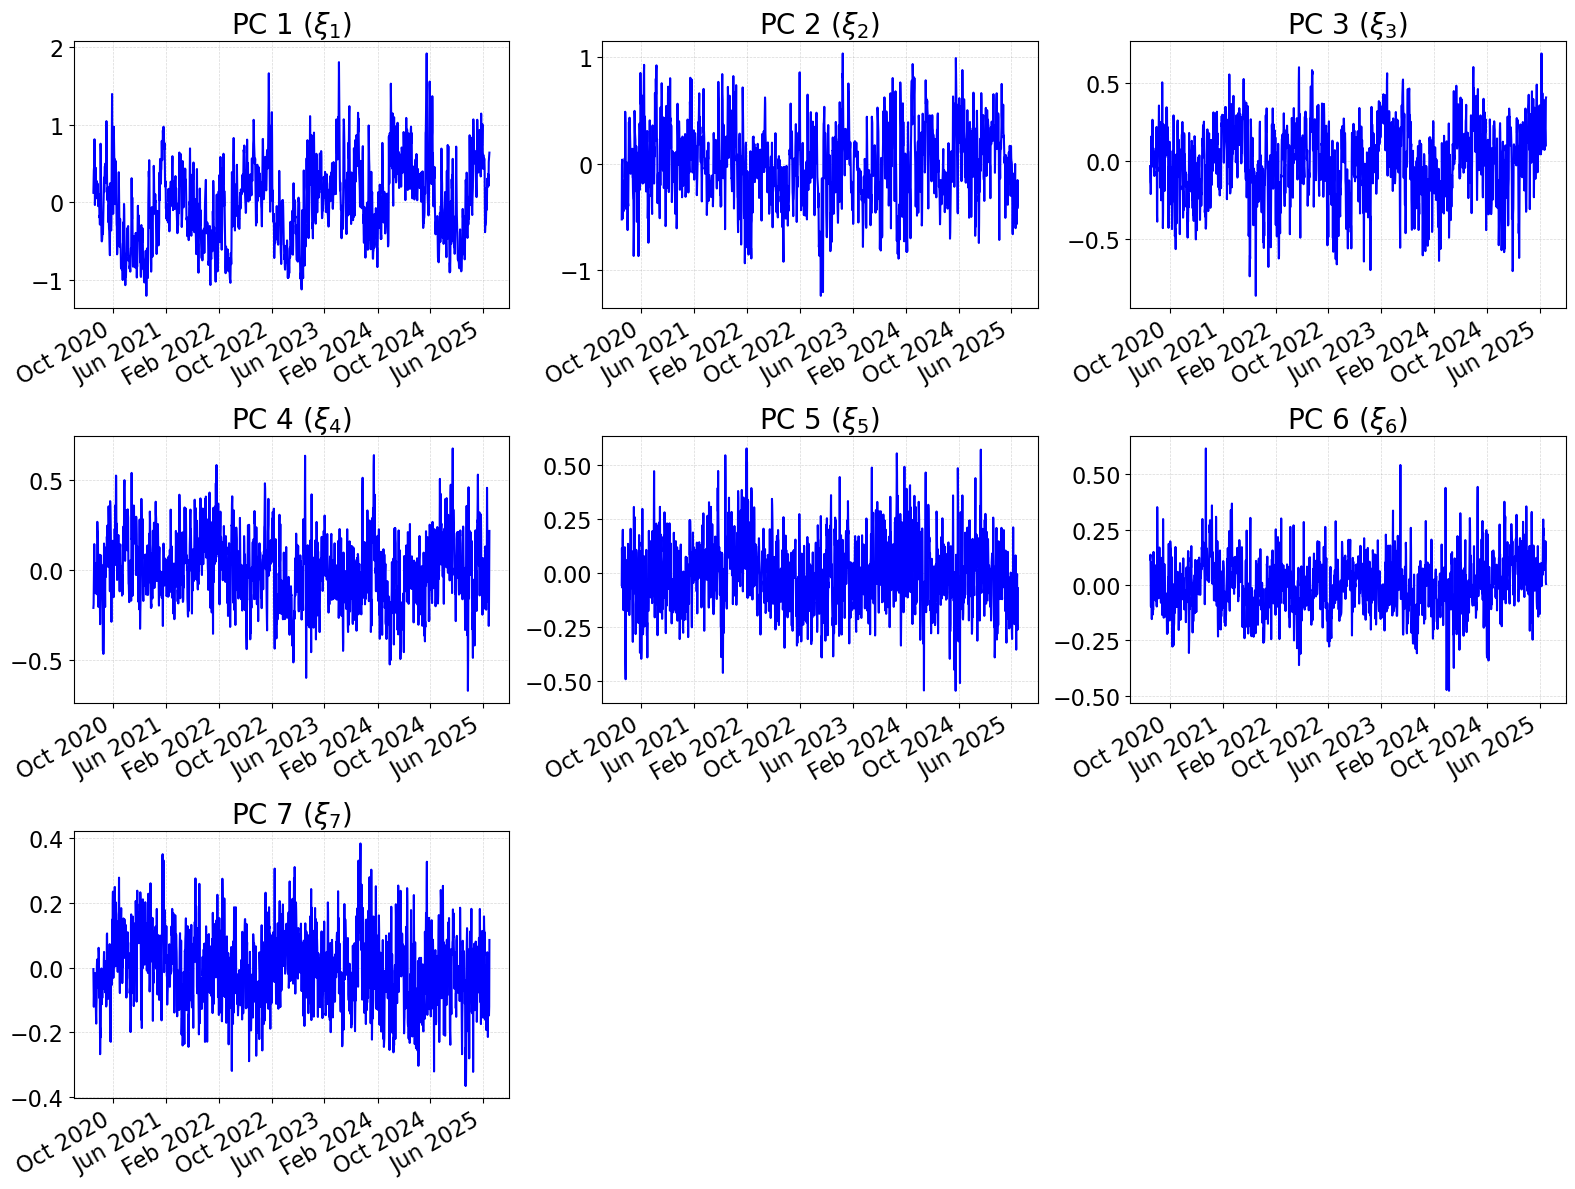

In [14]:
def plot_scores_compact():
    ymin = Xi_truncated[:, :r].min()
    ymax = Xi_truncated[:, :r].max()

    fig, axes = plt.subplots(3, 3, figsize=(16, 12), sharex=False)
    axes = axes.flatten()

    for i in range(r):
        ax = axes[i]

        ax.plot(
            dates[:-365],
            Xi_truncated[:, i],
            color='blue',
            linewidth=1.5
        )

        ax.set_title(fr"PC {i+1} ($\xi_{i+1}$)", fontsize=20)
        ax.grid(color='grey', linestyle='--', linewidth=0.5, alpha=0.3)
        ax.tick_params(axis='both', labelsize=16)

        if i < 10:  # top row
            ax.tick_params(labelbottom=True)
            ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
            ax.xaxis.set_major_locator(mdates.MonthLocator(interval=8))
        else:       # bottom row (keep same formatting, but no labels on top row duplication)
            ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
            ax.xaxis.set_major_locator(mdates.MonthLocator(interval=8))

    # Optional: rotate for readability (especially helpful with wide layout)
    for ax in axes:
        for label in ax.get_xticklabels():
            label.set_rotation(30)
            label.set_ha('right')

    for ax in axes[r:]:
        ax.set_axis_off()
    plt.tight_layout()
    plt.show()

plot_scores_compact()